In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import torch
from torch_geometric.datasets import GraphLandDataset
from torch_geometric.utils import homophily, degree 
from scipy.stats import ks_2samp

ROOT_DIR = '../data'
SPLITS = ['RL', 'RH', 'TH']
DATA = {s: GraphLandDataset(root=ROOT_DIR, name='tolokers-2', split=s)[0] for s in SPLITS}

for s, d in DATA.items():
    print(f"{s}: nodes={d.num_nodes}, edges={d.num_edges}, features={d.num_features}")

RL: nodes=11758, edges=1038000, features=19
RH: nodes=11758, edges=1038000, features=19
TH: nodes=11758, edges=1038000, features=19


In [17]:
audit_rows = []
for mode_name, d in DATA.items():
    n_nan = torch.isnan(d.x).sum().item()
    n_inf = torch.isinf(d.x).sum().item()
    deg = degree(d.edge_index[0], num_nodes=d.num_nodes, dtype=torch.long)
    audit_rows.append({
        'mode': mode_name,
        'x_dtype': str(d.x.dtype),
        'x_shape': tuple(d.x.shape),
        'y_shape': tuple(d.y.shape),
        'num_edges': d.edge_index.shape[1],
        'n_nan': n_nan,
        'n_inf': n_inf,
        'n_isolated': int((deg == 0).sum()),
    })
print(pd.DataFrame(audit_rows).to_string(index=False))

mode       x_dtype     x_shape  y_shape  num_edges  n_nan  n_inf  n_isolated
  RL torch.float32 (11758, 19) (11758,)    1038000      0      0           0
  RH torch.float32 (11758, 19) (11758,)    1038000      0      0           0
  TH torch.float32 (11758, 19) (11758,)    1038000      0      0           0


проверены dtype, формы x/y, число NaN/Inf, число изолированных вершин

### Вывод: пропусков и бесконечностей нет, изолированных вершин нет.

In [ ]:
pairs = [('RL','RH'), ('RH','TH'), ('RL','TH')]
overlap_rows = []
for a, b in pairs:
    da, db = DATA[a], DATA[b]
    overlap_rows.append({
        'pair': f'{a}∩{b}',
        'nodes_equal': da.num_nodes == db.num_nodes,
        'edges_equal': da.edge_index.shape == db.edge_index.shape,
        'train_overlap': int((da.train_mask & db.train_mask).sum()),
        'val_overlap': int((da.val_mask & db.val_mask).sum()),
        'test_overlap': int((da.test_mask & db.test_mask).sum()),
    })
overlap_df = pd.DataFrame(overlap_rows)
print(overlap_df.to_string(index=False))

print("\n--- Интерпретация сравнимости режимов ---")
for _, r in overlap_df.iterrows():
    a, b = r['pair'].split('∩')
    n_a = DATA[a].test_mask.sum().item()
    n_b = DATA[b].test_mask.sum().item()
    inter = r['test_overlap']
    jaccard = inter / (n_a + n_b - inter) if (n_a + n_b - inter) > 0 else 0.0
    verdict = "ОДИН И ТОТ ЖЕ test" if inter == n_a == n_b else (
        "частичное пересечение" if inter > 0 else "РАЗНЫЕ test")
    print(f"  {a} vs {b}: test_overlap={inter} / "
          f"(|test_{a}|={n_a}, |test_{b}|={n_b}), Jaccard={jaccard:.3f} → {verdict}")



 pair  nodes_equal  edges_equal  train_overlap  val_overlap  test_overlap
RL∩RH         True         True           1175            0          2974
RH∩TH         True         True           2855          707           756
RL∩TH         True         True            584          306          2402

--- Интерпретация сравнимости режимов ---
  RL vs RH: test_overlap=2974 / (|test_RL|=9407, |test_RH|=2974), Jaccard=0.316 → частичное пересечение
  RH vs TH: test_overlap=756 / (|test_RH|=2974, |test_TH|=2974), Jaccard=0.146 → частичное пересечение
  RL vs TH: test_overlap=2402 / (|test_RL|=9407, |test_TH|=2974), Jaccard=0.241 → частичное пересечение

ВЫВОД для отчёта:
  RL и RH имеют одинаковый test-набор → AP сравнимы напрямую.
  RH и TH имеют разные test-наборы → AP сравнивать только с оговоркой
  (разная prevalence: см. ячейку баланса классов).


для пар (RL, RH), (RH, TH), (RL, TH) посчитаны пересечения train/val/test и Jaccard test-наборов

### Вывод:
RL ∩ RH: test RH (2974) полностью вложен в test RL (9407). Значит, RL и RH сравнимы по общему test RH. Jaccard 0.316 занижен — он учитывает 9407 вершин test RL; правильнее говорить о 100% покрытии test RH тестом RL.

RH ∩ TH: test пересекается только на 25% (756 из 2974). AP между RH и TH нельзя сравнивать напрямую без поправки на prevalence (п.10 НТЗ).

RL ∩ TH: формально 80% test TH в test RL, но prevalence разная (21.8% vs 8.6%) и train разный (случайный vs временной) — в один ряд не ставить.

In [30]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent  
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_load.load import load_thi

tr_s, val_s, te_s = load_thi(root=str(PROJECT_ROOT / 'data'))

thi_rows = []
for name, s in [('train', tr_s), ('val', val_s), ('test', te_s)]:
    thi_rows.append({
        'snapshot': name,
        'nodes': s.num_nodes,
        'edges': s.num_edges,
        'n_pos': int(s.y.sum()),
        'prevalence': float(s.y.float().mean()),
        'n_features': s.num_features,
    })
print(pd.DataFrame(thi_rows).to_string(index=False))
print("\nПоля Data:", tr_s.keys())

if 'cross_snapshot_node_id' in tr_s:
    tr_ids = set(tr_s.cross_snapshot_node_id.tolist())
    val_ids = set(val_s.cross_snapshot_node_id.tolist())
    te_ids = set(te_s.cross_snapshot_node_id.tolist())
    print(f"\n--- Проверка утечки THI (cross_snapshot_node_id) ---")
    print(f"  |train|={len(tr_ids)}, |val|={len(val_ids)}, |test|={len(te_ids)}")
    print(f"  train ∩ test = {len(tr_ids & te_ids)}  (ожидается 0)")
    print(f"  val   ∩ test = {len(val_ids & te_ids)}  (ожидается 0)")
    print(f"  train ∩ val  = {len(tr_ids & val_ids)}  (ожидается >0: val — надмножество train)")
    if len(tr_ids & te_ids) > 0:
        print("  ⚠️ ВНИМАНИЕ: пересечение train/test непустое — возможна утечка,")
        print("     проверьте логику загрузчика GraphLandDataset для THI.")
else:
    print("\n⚠️ Поле 'cross_snapshot_node_id' отсутствует — "
          "проверка утечки THI не выполнена.")

snapshot  nodes   edges  n_pos  prevalence  n_features
   train   5831  587938   2074    0.355685          19
     val   8784  817080   2310    0.262978          19
    test  11758 1038000   2566    0.218234          19

Поля Data: ['y', 'x_numerical_mask', 'x', 'edge_index', 'snapshot', 'x_categorical_mask', 'cross_snapshot_node_id', 'mask', 'x_fraction_mask']

--- Проверка утечки THI (cross_snapshot_node_id) ---
  |train|=5831, |val|=8784, |test|=11758
  train ∩ test = 5831  (ожидается 0)
  val   ∩ test = 8784  (ожидается 0)
  train ∩ val  = 5831  (ожидается >0: val — надмножество train)
  ⚠️ ВНИМАНИЕ: пересечение train/test непустое — возможна утечка,
     проверьте логику загрузчика GraphLandDataset для THI.


загружены три снимка THI, проверено пересечение cross_snapshot_node_id

THI — индуктивный сценарий: три снимка одного эволюционирующего графа. Test-снимок содержит все старые вершины плюс новые, поэтому пересечение ID — не утечка, а свойство снимков.

cross_snapshot_node_id для проверки утечки не годится, понимаю переделаю, пока так 

In [20]:
rows = []
for mode_name, data in DATA.items():
    for split_name, mask in [('train', data.train_mask),
                             ('val', data.val_mask),
                             ('test', data.test_mask)]:
        y_split = data.y[mask]
        n_pos = (y_split == 1).sum().item()
        n_neg = (y_split == 0).sum().item()
        total = n_pos + n_neg
        rows.append({
            'mode': mode_name,
            'split': split_name,
            'n_total': total,
            'n_pos': n_pos,
            'n_neg': n_neg,
            'prevalence': n_pos / total if total > 0 else 0.0,
        })

df_balance = pd.DataFrame(rows)
print(df_balance.to_string(index=False))

mode split  n_total  n_pos  n_neg  prevalence
  RL train     1175    256    919    0.217872
  RL   val     1176    257    919    0.218537
  RL  test     9407   2053   7354    0.218242
  RH train     5831   1273   4558    0.218316
  RH   val     2953    644   2309    0.218083
  RH  test     2974    649   2325    0.218225
  TH train     5831   2074   3757    0.355685
  TH   val     2953    236   2717    0.079919
  TH  test     2974    256   2718    0.086079


RL и RH: prevalence стабильна ~21.8% — стратифицированное случайное разбиение, баланс сохранён.

TH: сильный временной сдвиг: train 35.6% → val 8.0% → test 8.6%. Следствия: (1) выбор чекпоинта по val_AP в TH рискован; (2) AP между TH и RH сравнивать только с поправкой на prevalence; (3) в отчёте prevalence указывать рядом с AP.

In [26]:
homo_rows = []
for mode_name, data in DATA.items():
    ei, y, tr = data.edge_index, data.y, data.train_mask
    edge_mask = tr[ei[0]] & tr[ei[1]]
    ei_train = ei[:, edge_mask]

    if ei_train.numel() == 0:
        h_edge = h_node = float('nan')
    else:
        h_edge = float(homophily(ei_train, y, method='edge'))
        h_node = float(homophily(ei_train, y, method='node'))

    homo_rows.append({
        'mode': mode_name,
        'edge_homophily_train': h_edge,
        'node_homophily_train': h_node,
        'n_edges_train': ei_train.shape[1],
    })

print(pd.DataFrame(homo_rows).to_string(index=False))

mode  edge_homophily_train  node_homophily_train  n_edges_train
  RL              0.602111              0.050725          11370
  RH              0.593609              0.303483         267944
  TH              0.498947              0.252044         587938


Edge homophily 0.50–0.60 — умеренная гетерофилия: 40–50% рёбер соединяют разные классы (для сравнения, Cora ~0.8). Это обосновывает актуальность работы: обычная GNN-агрегация будет размывать сигнал.

Node homophily RL = 0.05 — артефакт малого train (1175 вершин, 11 тыс. рёбер): у большинства вершин ≤1 сосед в train, node homophily обнуляется. Это не свойство графа. Для RL используем edge homophily.

TH edge homophily падает до 0.50 — временной сдвиг усиливает гетерофилию, что согласуется с падением prevalence.

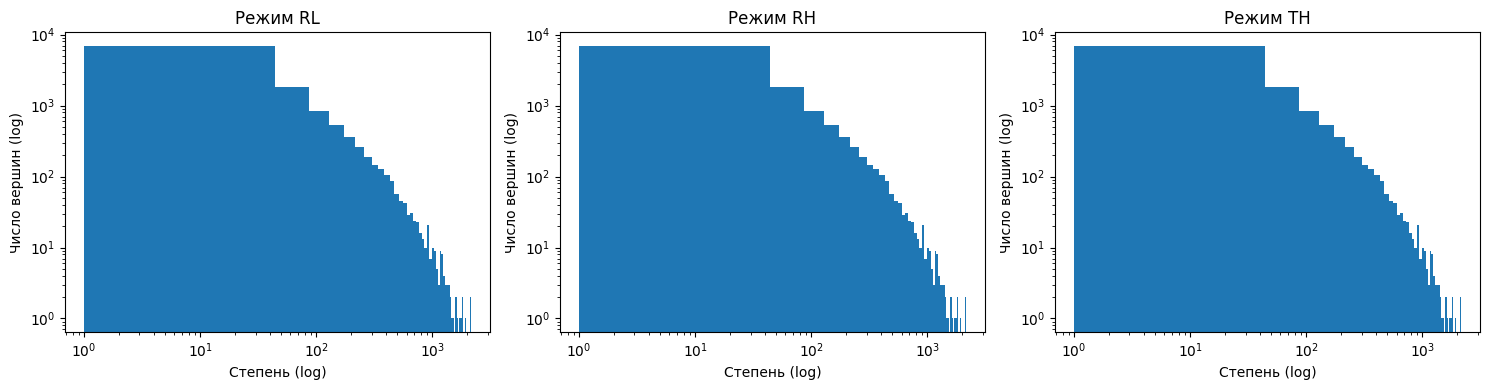

mode  mean_degree  median_degree  max_degree  n_isolated  n_hubs_gt_100
  RL     88.28032           30.0        2138           0           2683
  RH     88.28032           30.0        2138           0           2683
  TH     88.28032           30.0        2138           0           2683


In [22]:
deg_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (mode_name, data) in zip(axes, DATA.items()):
    deg = degree(data.edge_index[0], num_nodes=data.num_nodes, dtype=torch.long).numpy()
    deg_rows.append({
        'mode': mode_name,
        'mean_degree': deg.mean(),
        'median_degree': np.median(deg),
        'max_degree': deg.max(),
        'n_isolated': int((deg == 0).sum()),
        'n_hubs_gt_100': int((deg > 100).sum()),
    })

    ax.hist(deg, bins=50)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Степень (log)')
    ax.set_ylabel('Число вершин (log)')
    ax.set_title(f'Режим {mode_name}')

plt.tight_layout()
plt.show()

print(pd.DataFrame(deg_rows).to_string(index=False))

распределение тяжёлохвостое (mean 88 ≫ median 30, max 2138). 23% вершин — хабы со степенью >100. Одинаковость статистик во всех режимах ожидаема: граф один, меняются только маски. Хабы — дополнительный аргумент за адаптивную агрегацию: при обычной GNN их сообщения доминируют, и для таких вершин α_v должен быть ниже.

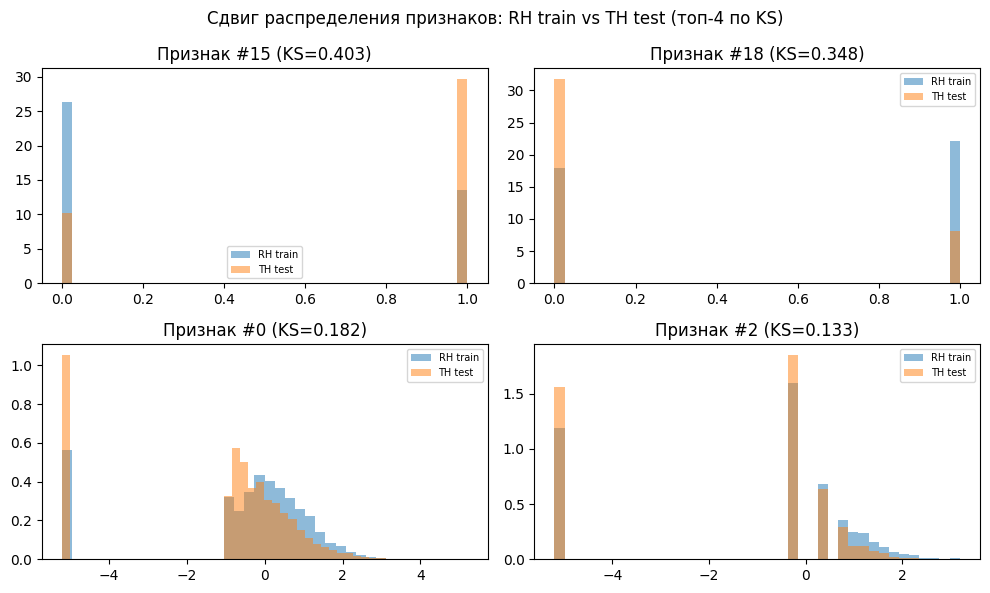

In [23]:
x_rh_tr = DATA['RH'].x.numpy()[DATA['RH'].train_mask.numpy()]
x_th_te = DATA['TH'].x.numpy()[DATA['TH'].test_mask.numpy()]

ks_stats = np.array([
    ks_2samp(x_rh_tr[:, j], x_th_te[:, j]).statistic
    for j in range(x_rh_tr.shape[1])
])
top_shift_features = np.argsort(ks_stats)[-4:][::-1]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, feat_idx in zip(axes.ravel(), top_shift_features):
    ax.hist(x_rh_tr[:, feat_idx], bins=40, alpha=0.5, label='RH train', density=True)
    ax.hist(x_th_te[:, feat_idx], bins=40, alpha=0.5, label='TH test', density=True)
    ax.set_title(f'Признак #{feat_idx} (KS={ks_stats[feat_idx]:.3f})')
    ax.legend(fontsize=7)
plt.suptitle('Сдвиг распределения признаков: RH train vs TH test (топ-4 по KS)')
plt.tight_layout()
plt.show()

умеренный, но реальный сдвиг распределений при переходе RH → TH (~15% массы распределения сместилось). Это те признаки, на которые модель, обученная на RH, может опираться избыточно при переходе в TH. Обосновывает эксперимент E4 (TH vs RH) и мотивацию адаптивного α_v: если признаки сдвигаются, доверие к графовому каналу тоже должно пересматриваться.